# Exploratory Data Analysis

In [1]:
import os
import sys

sys.path.append('../src')

import dask.dataframe as dd
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from data_loader import (
    download_dataset,
    load_orders,
    load_interactions,
    load_items,
    load_categories
)

plt.style.use('seaborn-v0_8')
sns.set_palette("husl")

## Загрузка датасета

In [2]:
download_dataset()

Датасет загружен ранее


## Анализ данных

### Информация о заказах:
- ml_ozon_recsys_train_final_apparel_orders_data
- archive_extra_orders_data/archive_extra_orders_data

#### Информация о заказах с 1 января по 1 июля:
- ml_ozon_recsys_train_final_apparel_orders_data

In [3]:
# В каталоге ml_ozon_recsys_train_final_apparel_orders_data 5 parquet файлов
os.listdir('../data/ml_ozon_recsys_train_final_apparel_orders_data')

['part-00000-7b718cf5-560c-4ace-bbb7-e36ef433637b-c000.snappy.parquet',
 'part-00001-7b718cf5-560c-4ace-bbb7-e36ef433637b-c000.snappy.parquet',
 'part-00002-7b718cf5-560c-4ace-bbb7-e36ef433637b-c000.snappy.parquet',
 'part-00003-7b718cf5-560c-4ace-bbb7-e36ef433637b-c000.snappy.parquet',
 'part-00004-7b718cf5-560c-4ace-bbb7-e36ef433637b-c000.snappy.parquet',
 '_SUCCESS']

In [4]:
orders_ddf = load_orders(train=True)

In [5]:
print("АНАЛИЗ ЗАКАЗОВ")
print("=" * 50)
print("Общее количество заказов: {:,}".format(orders_ddf.shape[0].compute()))
print("Уникальных пользователей: {:,}".format(orders_ddf['user_id'].nunique().compute()))
print("Уникальных товаров:       {:,}".format(orders_ddf['item_id'].nunique().compute()))
print("Период данных:            {} - {}".format(
    orders_ddf['created_date'].min().compute(),
    orders_ddf['created_date'].max().compute()
    ))

print("\nРаспределение статусов заказов:")
status_counts = orders_ddf['last_status'].value_counts().compute()
status_counts_df = pd.DataFrame(status_counts.sort_values(ascending=False))
status_counts_df['percentage'] = status_counts_df['count'].apply(
    lambda x: f"{x/status_counts_df['count'].sum():.2%}")
status_counts_df.index.name = None
print(status_counts_df)

АНАЛИЗ ЗАКАЗОВ
Общее количество заказов: 18,887,122
Уникальных пользователей: 834,137
Уникальных товаров:       4,673,763
Период данных:            2025-01-01 - 2025-07-01

Распределение статусов заказов:
                    count percentage
delivered_orders  9936249     52.61%
canceled_orders   7990577     42.31%
proccesed_orders   960296      5.08%


#### Информация о заказах с 2 по 15 июля:
- archive_extra_orders_data/final_apparel_orders_data_07

In [6]:
# В каталоге archive_extra_orders_data/final_apparel_orders_data_07 14 партиций (по датам)
orders_files_new = os.listdir('../data/archive_extra_orders_data/final_apparel_orders_data_07')
for partition in orders_files_new:
    print('В партиции {} {} parquet файла'.format(
        partition, len(os.listdir(f'../data/archive_extra_orders_data/final_apparel_orders_data_07/{partition}'))
    ))

В партиции created_date=2025-07-02 2 parquet файла
В партиции created_date=2025-07-03 2 parquet файла
В партиции created_date=2025-07-04 2 parquet файла
В партиции created_date=2025-07-05 2 parquet файла
В партиции created_date=2025-07-06 2 parquet файла
В партиции created_date=2025-07-07 2 parquet файла
В партиции created_date=2025-07-08 2 parquet файла
В партиции created_date=2025-07-09 2 parquet файла
В партиции created_date=2025-07-10 2 parquet файла
В партиции created_date=2025-07-11 2 parquet файла
В партиции created_date=2025-07-12 2 parquet файла
В партиции created_date=2025-07-13 2 parquet файла
В партиции created_date=2025-07-14 2 parquet файла
В партиции created_date=2025-07-15 2 parquet файла


In [7]:
orders_new_ddf = load_orders(train=False)

In [8]:
print("АНАЛИЗ ЗАКАЗОВ")
print("=" * 50)
print("Общее количество заказов: {:,}".format(orders_new_ddf.shape[0].compute()))
print("Уникальных пользователей: {:,}".format(orders_new_ddf['user_id'].nunique().compute()))
print("Уникальных товаров:       {:,}".format(orders_new_ddf['item_id'].nunique().compute()))
print("Период данных:            {} - {}".format(
    dd.to_datetime(orders_new_ddf["created_date"]).min().compute().date(),
    dd.to_datetime(orders_new_ddf["created_date"]).max().compute().date()
    ))

print("\nРаспределение статусов заказов:")
status_counts_new = orders_new_ddf['last_status'].value_counts().compute()
status_counts_new_df = pd.DataFrame(status_counts_new.sort_values(ascending=False))
status_counts_new_df['percentage'] = status_counts_new_df['count'].apply(
    lambda x: f"{x/status_counts_new_df['count'].sum():.2%}")
status_counts_new_df.index.name = None
print(status_counts)

АНАЛИЗ ЗАКАЗОВ
Общее количество заказов: 1,475,216
Уникальных пользователей: 346,759
Уникальных товаров:       692,335
Период данных:            2025-07-02 - 2025-07-15

Распределение статусов заказов:
last_status
canceled_orders     7990577
delivered_orders    9936249
proccesed_orders     960296
Name: count, dtype: int64[pyarrow]


### Информация о взаимодействиях:
- ml_ozon_recsys_train_final_apparel_tracker_data
- final_apparel_tracker_data_08_action_widget

#### Информация о взаимодействиях с 1 января по 1 июля:
- ml_ozon_recsys_train_final_apparel_tracker_data

In [9]:
# В каталоге ml_ozon_recsys_train_final_apparel_tracker_data 200 parquet файлов
tracker_files = os.listdir('../data/ml_ozon_recsys_train_final_apparel_tracker_data')
len(tracker_files)
tracker_files[-5:]

['part-00196-582d88ee-8dd6-41f6-9f90-375910468cb7-c000.snappy.parquet',
 'part-00197-582d88ee-8dd6-41f6-9f90-375910468cb7-c000.snappy.parquet',
 'part-00198-582d88ee-8dd6-41f6-9f90-375910468cb7-c000.snappy.parquet',
 'part-00199-582d88ee-8dd6-41f6-9f90-375910468cb7-c000.snappy.parquet',
 '_SUCCESS']

In [10]:
tracker_ddf = load_interactions(train=True)

In [11]:
print("\n АНАЛИЗ ВЗАИМОДЕЙСТВИЙ")
print("=" * 50)
print("Общее количество взаимодействий: {:,}".format(tracker_ddf.shape[0].compute()))
print("Уникальных пользователей:        {:,}".format(tracker_ddf['user_id'].nunique().compute()))
print("Уникальных товаров:              {:,}".format(tracker_ddf['item_id'].nunique().compute()))
print("Период данных:                   {} - {}".format(
    tracker_ddf["date"].min().compute(),
    tracker_ddf["date"].max().compute()
    ))

print("\nРаспределение типов действий:")
action_counts = tracker_ddf['action_type'].value_counts().compute()
action_counts_df = pd.DataFrame(action_counts.sort_values(ascending=False))
action_counts_df['percentage'] = action_counts_df['count'].apply(
    lambda x: f"{x/action_counts_df['count'].sum():.2%}")
action_counts_df.index.name = None
print(action_counts_df)


 АНАЛИЗ ВЗАИМОДЕЙСТВИЙ
Общее количество взаимодействий: 1,644,982,482
Уникальных пользователей:        1,011,099
Уникальных товаров:              4,895,557
Период данных:                   2025-01-01 - 2025-07-01

Распределение типов действий:
                       count percentage
page_view         1176606537     71.53%
view_description   221879384     13.49%
review_view         76459985      4.65%
to_cart             61059905      3.71%
favorite            51948578      3.16%
remove              37207155      2.26%
unfavorite          19820938      1.20%


In [12]:
# Имеются некорректные timestamp взаимодействий
print('Количество записей из прошлого: {}'.format(
    tracker_ddf[tracker_ddf['timestamp'] <= '2024-12-31'].shape[0].compute()))
tracker_ddf[tracker_ddf['timestamp'] <= '2023-12-31'].head(3, npartitions=-1)

Количество записей из прошлого: 3783


,item_id,user_id,timestamp,action_type,action_widget,date
7152743,275406581,4625880,2019-04-28 07:04:24,view_description,pdp.webCharacteristics,2025-04-28
7152755,275406581,4625880,2019-04-28 07:04:24,page_view,shelf.buyTogether,2025-04-28
217062,203708971,3534281,2022-02-20 02:14:05,view_description,pdp.webCharacteristics,2025-06-28


In [13]:
# Имеются некорректные timestamp взаимодействий
print('Количество записей из будущего: {}'.format(
    tracker_ddf[tracker_ddf['timestamp'] >= '2025-07-02'].shape[0].compute()))
tracker_ddf[tracker_ddf['timestamp'] >= '2026-01-01'].head(3, npartitions=-1)

Количество записей из будущего: 2363


,item_id,user_id,timestamp,action_type,action_widget,date
2037137,220466124,834400,2027-02-04 00:57:00,page_view,shelf.analogShelf,2025-06-23
2037138,220466124,834400,2027-02-04 00:57:03,view_description,pdp.webCharacteristics,2025-06-23
2037144,220466124,834400,2027-02-04 00:57:01,view_description,pdp.webCharacteristics,2025-06-23


#### Информация о взаимодействиях с 2 по 15 июля:
- final_apparel_tracker_data_08_action_widget

In [14]:
# В каталоге final_apparel_tracker_data_08_action_widget 14 партиций (по датам)
tracker_new_files = os.listdir('../data/final_apparel_tracker_data_08_action_widget')
for partition in tracker_new_files:
    print('В партиции {} {} parquet файлов'.format(
        partition, len(os.listdir(f'../data/final_apparel_tracker_data_08_action_widget/{partition}'))
    ))

В партиции date=2025-07-02 200 parquet файлов
В партиции date=2025-07-03 200 parquet файлов
В партиции date=2025-07-04 200 parquet файлов
В партиции date=2025-07-05 200 parquet файлов
В партиции date=2025-07-06 200 parquet файлов
В партиции date=2025-07-07 200 parquet файлов
В партиции date=2025-07-08 200 parquet файлов
В партиции date=2025-07-09 200 parquet файлов
В партиции date=2025-07-10 200 parquet файлов
В партиции date=2025-07-11 200 parquet файлов
В партиции date=2025-07-12 200 parquet файлов
В партиции date=2025-07-13 200 parquet файлов
В партиции date=2025-07-14 200 parquet файлов
В партиции date=2025-07-15 200 parquet файлов


In [15]:
tracker_new_ddf = load_interactions(train=False)

In [16]:
print("\n АНАЛИЗ ВЗАИМОДЕЙСТВИЙ")
print("=" * 50)
print("Общее количество взаимодействий: {:,}".format(tracker_new_ddf.shape[0].compute()))
print("Уникальных пользователей:        {:,}".format(tracker_new_ddf['user_id'].nunique().compute()))
print("Уникальных товаров:              {:,}".format(tracker_new_ddf['item_id'].nunique().compute()))
print("Период данных:                   {} - {}".format(
    dd.to_datetime(tracker_new_ddf["date"]).min().compute().date(),
    dd.to_datetime(tracker_new_ddf["date"]).max().compute().date()
    ))

print("\nРаспределение типов действий:")
action_counts_new = tracker_new_ddf['action_type'].value_counts().compute()
action_counts_new_df = pd.DataFrame(action_counts_new.sort_values(ascending=False))
action_counts_new_df['percentage'] = action_counts_new_df['count'].apply(
    lambda x: f"{x/action_counts_new_df['count'].sum():.2%}")
action_counts_new_df.index.name = None
print(action_counts_new_df)


 АНАЛИЗ ВЗАИМОДЕЙСТВИЙ
Общее количество взаимодействий: 116,537,514
Уникальных пользователей:        807,653
Уникальных товаров:              3,197,872
Период данных:                   2025-07-02 - 2025-07-15

Распределение типов действий:
                     count percentage
page_view         80595085     69.16%
view_description  17253961     14.81%
review_view        5729054      4.92%
to_cart            4613925      3.96%
favorite           3454652      2.96%
remove             3007494      2.58%
unfavorite         1883343      1.62%


In [17]:
# Имеются некорректные timestamp взаимодействий
print('Количество записей из прошлого: {}'.format(
    tracker_new_ddf[tracker_new_ddf['timestamp'] <= '2025-07-01'].shape[0].compute()))
tracker_new_ddf[tracker_new_ddf['timestamp'] <= '2025-06-01'].head(3, npartitions=-1)

Количество записей из прошлого: 926


,action_widget,item_id,user_id,timestamp,action_type,date
19207,pdp.webCharacteristics,205234237,3467850,2025-04-11 12:58:54,view_description,2025-07-02
19208,shelf.userHistory,205234237,3467850,2025-04-11 12:58:53,page_view,2025-07-02
21613,pdp.webMobRichContent,122015772,3946580,2025-04-27 08:10:00,view_description,2025-07-02


In [18]:
# Имеются некорректные timestamp взаимодействий
print('Количество записей из будущего: {}'.format(
    tracker_new_ddf[tracker_new_ddf['timestamp'] >= '2025-07-16'].shape[0].compute()))
tracker_new_ddf[tracker_new_ddf['timestamp'] >= '2025-07-16'].head(3, npartitions=-1)

Количество записей из будущего: 1181


,action_widget,item_id,user_id,timestamp,action_type,date
2068,catalog.searchResultsV2,174293145,2283521,2025-07-16 09:16:32,page_view,2025-07-12
21895,catalog.searchResultsV2,138665833,2283521,2025-07-16 12:08:47,page_view,2025-07-12
21896,catalog.searchResultsV2,138665833,2283521,2025-07-16 12:05:55,page_view,2025-07-12


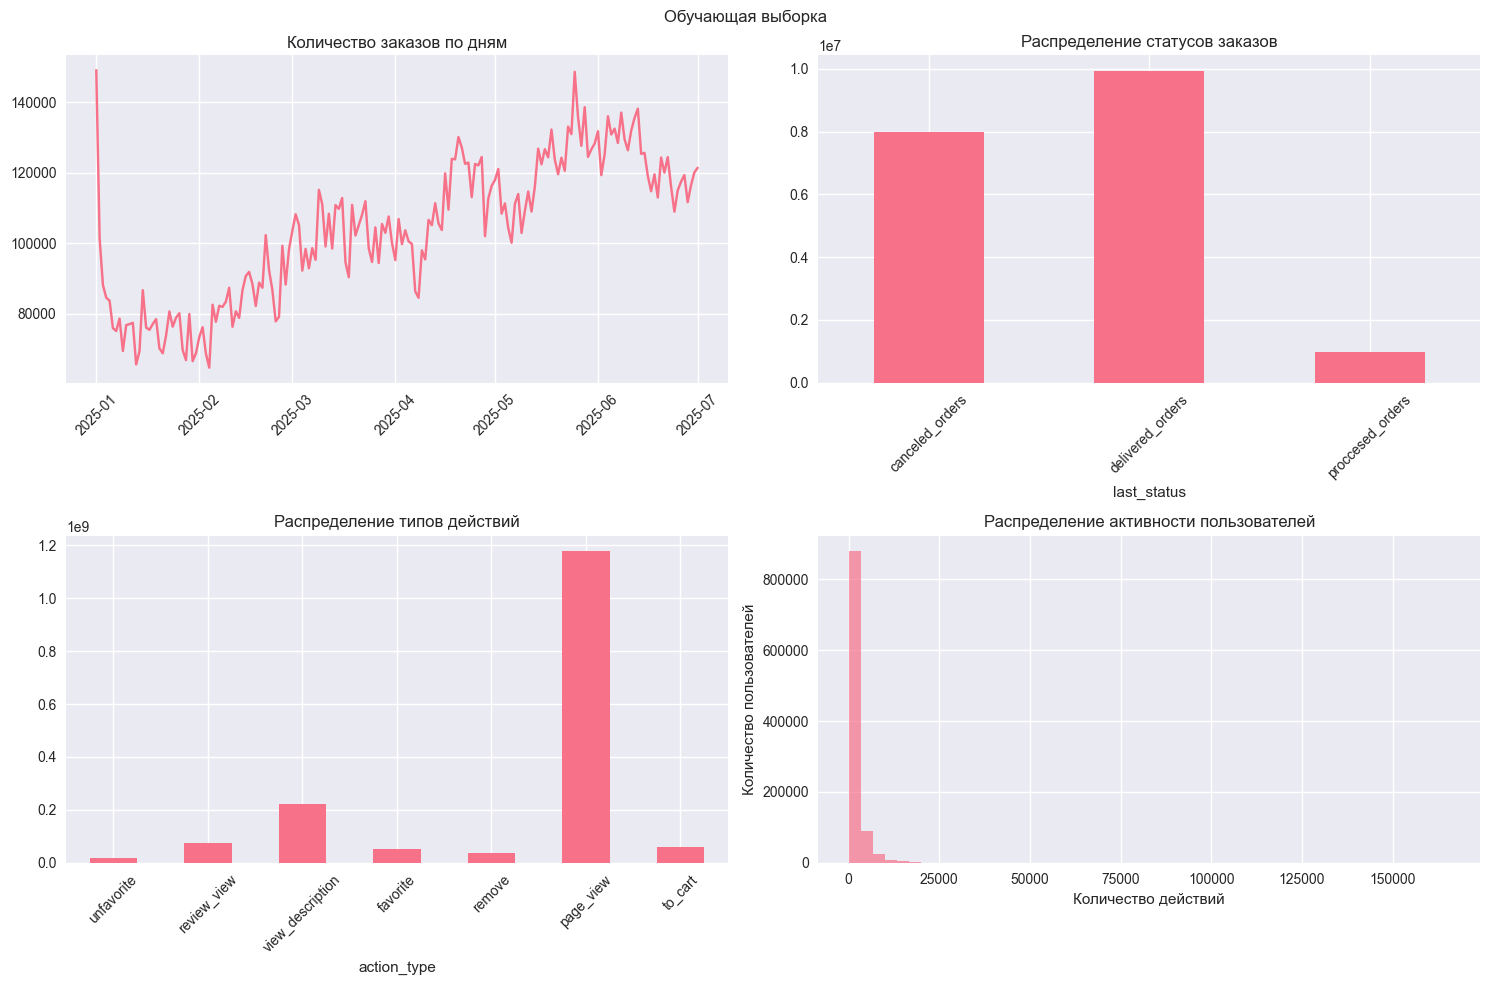

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

orders_ddf['created_date'] = dd.to_datetime(orders_ddf['created_date'])
daily_orders = orders_ddf.groupby('created_date').size().compute()
axes[0, 0].plot(daily_orders.index, daily_orders.values)
axes[0, 0].set_title('Количество заказов по дням')
axes[0, 0].tick_params(axis='x', rotation=45)

status_counts.plot(kind='bar', ax=axes[0, 1])
axes[0, 1].set_title('Распределение статусов заказов')
axes[0, 1].tick_params(axis='x', rotation=45)

action_counts.plot(kind='bar', ax=axes[1, 0])
axes[1, 0].set_title('Распределение типов действий')
axes[1, 0].tick_params(axis='x', rotation=45)

user_activity = tracker_ddf['user_id'].value_counts().compute()
axes[1, 1].hist(user_activity.values, bins=50, alpha=0.7)
axes[1, 1].set_title('Распределение активности пользователей')
axes[1, 1].set_xlabel('Количество действий')
axes[1, 1].set_ylabel('Количество пользователей')

fig.suptitle("Обучающая выборка")
plt.tight_layout()
plt.show()

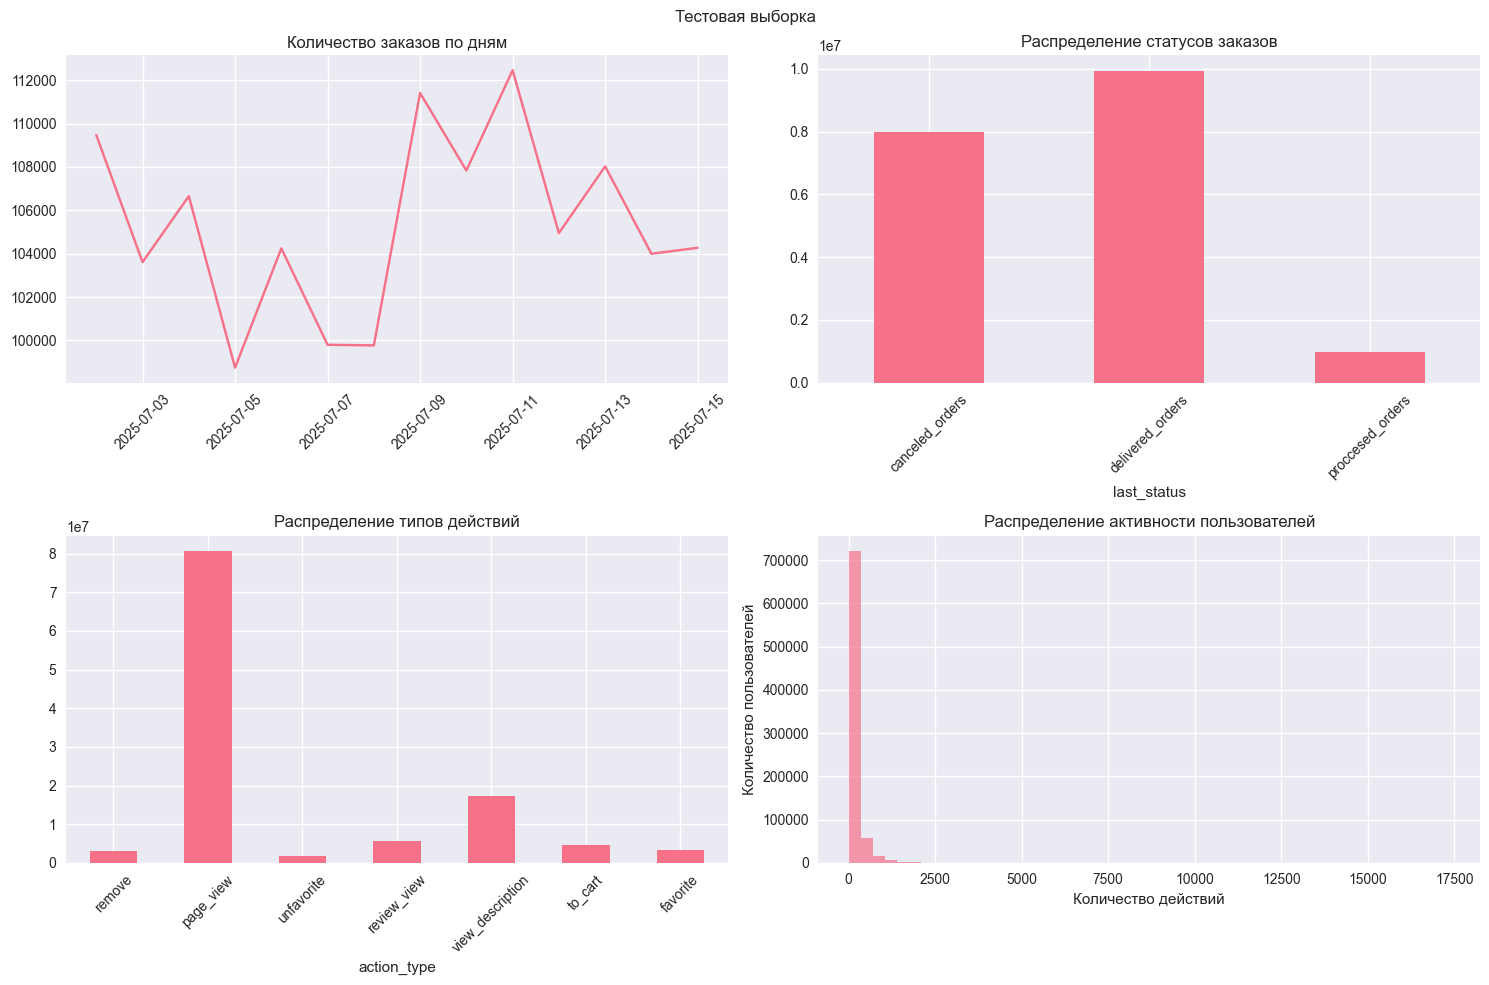

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

orders_new_ddf['created_date'] = dd.to_datetime(orders_new_ddf['created_date'])
daily_new_orders = orders_new_ddf.groupby('created_date').size().compute()
axes[0, 0].plot(daily_new_orders.index, daily_new_orders.values)
axes[0, 0].set_title('Количество заказов по дням')
axes[0, 0].tick_params(axis='x', rotation=45)

status_counts.plot(kind='bar', ax=axes[0, 1])
axes[0, 1].set_title('Распределение статусов заказов')
axes[0, 1].tick_params(axis='x', rotation=45)

action_counts_new.plot(kind='bar', ax=axes[1, 0])
axes[1, 0].set_title('Распределение типов действий')
axes[1, 0].tick_params(axis='x', rotation=45)

user_activity_new = tracker_new_ddf['user_id'].value_counts().compute()
axes[1, 1].hist(user_activity_new.values, bins=50, alpha=0.7)
axes[1, 1].set_title('Распределение активности пользователей')
axes[1, 1].set_xlabel('Количество действий')
axes[1, 1].set_ylabel('Количество пользователей')

fig.suptitle("Тестовая выборка")
plt.tight_layout()
plt.show()

### Информация о товарах:
- ml_ozon_recsys_train_final_apparel_items_data

In [21]:
# В каталоге ml_ozon_recsys_train_final_apparel_items_data 100 parquet файлов
items_files = os.listdir('../data/ml_ozon_recsys_train_final_apparel_items_data')
len(items_files)
items_files[-5:]

['part-00096-5322ad28-d73d-4c69-86d2-4efc7ad4f422-c000.snappy.parquet',
 'part-00097-5322ad28-d73d-4c69-86d2-4efc7ad4f422-c000.snappy.parquet',
 'part-00098-5322ad28-d73d-4c69-86d2-4efc7ad4f422-c000.snappy.parquet',
 'part-00099-5322ad28-d73d-4c69-86d2-4efc7ad4f422-c000.snappy.parquet',
 '_SUCCESS']

In [22]:
items_ddf = load_items()

In [23]:
print("\nАНАЛИЗ ТОВАРОВ")
print("=" * 50)
print("Общее количество товаров: {:,}".format(items_ddf.shape[0].compute()))
print("Товары с названием:       {:,}".format((~items_ddf['itemname'].isna()).sum().compute()))
print("Товары с эмбеддингами:    {:,}".format((~items_ddf['fclip_embed'].isna()).sum().compute()))

print("\nТоп-10 категорий:")
top_categories = items_ddf['catalogid'].value_counts().compute().sort_values(ascending=False).head(10)
for cat_id, count in top_categories.items():
    print(f"  Категория  {cat_id}:\t{count:,}")


АНАЛИЗ ТОВАРОВ
Общее количество товаров: 6,439,422
Товары с названием:       6,439,422
Товары с эмбеддингами:    6,439,422

Топ-10 категорий:
  Категория  7559:	413,637
  Категория  7508:	267,444
  Категория  36484:	225,336
  Категория  7660:	219,858
  Категория  7502:	199,919
  Категория  7512:	120,846
  Категория  7511:	108,535
  Категория  7530:	106,773
  Категория  17002:	105,158
  Категория  7644:	101,622


### Каталог (категории) товаров:
- ml_ozon_recsys_train_final_categories_tree

In [24]:
# В каталоге ml_ozon_recsys_train_final_categories_tree 1 parquet файл
categories_files = os.listdir('../data/ml_ozon_recsys_train_final_categories_tree')
categories_files

['part-00000-163f9108-23d6-4fd6-98c4-7bcb73ee27e2-c000.snappy.parquet',
 '_SUCCESS']

In [25]:
categories_ddf = load_categories()

In [26]:
print('Датасет содержит:\n'
'  - {:,} записей\n'
'  - {:,} категорий товаров (catalogid)\n'.format(
    categories_ddf.shape[0].compute(),
    categories_ddf['catalogid'].nunique().compute()
    ))
categories_ddf.head()

Датасет содержит:
  - 7,012 записей
  - 7,012 категорий товаров (catalogid)



,catalogid,catalogpath,ids
0,15500,"[{'id': 15500, 'name': 'Электроника', 'fullNam...","[15500, -1]"
1,15501,"[{'id': 15501, 'name': 'Телефоны и смарт-часы'...","[15501, 15500, -1]"
2,15502,"[{'id': 15502, 'name': 'Смартфоны', 'fullName'...","[15502, 15501, 15500, -1]"
3,15511,"[{'id': 15511, 'name': 'Аксессуары для смартфо...","[15511, 15501, 15500, -1]"
4,15892,"[{'id': 15892, 'name': 'Чехлы', 'fullName': 'Ч...","[15892, 15511, 15501, 15500, -1]"


### Тестовые данные (id пользователей для рекомендаций)
- ml_ozon_recsys_test.snappy.parquet

In [27]:
test_ddf = dd.read_parquet(
    "../data/ml_ozon_recsys_test.snappy.parquet")

In [28]:
print('Датасет содержит:\n'
'  - {:,} записей\n'
'  - {:,} уникальных пользователей (user_id)\n'.format(
    test_ddf.shape[0].compute(),
    test_ddf['user_id'].nunique().compute()
    ))
test_ddf.head(3)

Датасет содержит:
  - 470,347 записей
  - 470,347 уникальных пользователей (user_id)



,user_id
0,1857340
1,4094281
2,4815130


## Разделение на обучающую и тестовую выборку

Тестовые данные содержат только user_id и не представляется возможным оценить качество рекомендаций для будущего периода.

Для обучения будет использованны данные о заказах и взаимодействиях с 1 января 2025 по 1 июля 2025

Для оценки будет использованны данные о заказах и взаимодействиях с 2 по 15 июля 2025